# Left-Handedness, Birth Cohorts & Age at Death
### MedTourEasy Data Analytics Project

**Objective**

Investigate whether the apparent difference in age at death between left- and right-handed groups can be explained by historical changes in reported left-handedness across birth cohorts.

**Core idea**

The analysis combines:

1. Historical left-handedness rates from the 1986 National Geographic survey.
2. A U.S. death distribution from 1999.
3. Bayesian probability to estimate age-at-death distributions conditional on handedness.
4. A modeled comparison of different **study years** (1990 and 2018).

> **Important interpretation:** The 2018 scenario does **not** use a 2018 mortality dataset or a new 2018 handedness survey. `study_year=2018` changes the mapping from age at death to birth cohort while the mortality distribution remains fixed.

## 1. Imports and plotting setup

The notebook uses only the libraries needed for data loading, numerical calculations, visualization, and notebook display.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
# Keep figures readable in a notebook.
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 2. Data sources

### Handedness data
The handedness dataset is derived from the 1986 National Geographic survey. It records reported left-handedness rates by age and sex.

### Mortality data
The mortality dataset contains the U.S. death distribution used in the original analysis. The `Both Sexes` column is the number of deaths at each age.

The model deliberately keeps this mortality distribution fixed when testing a different `study_year`.

In [3]:
# Original data sources used by the project.
LH_URL = (
    "https://gist.githubusercontent.com/mbonsma/"
    "8da0990b71ba9a09f7de395574e54df1/raw/"
    "aec88b30af87fad8d45da7e774223f91dad09e88/lh_data.csv"
)

MORTALITY_URL = (
    "https://gist.githubusercontent.com/mbonsma/"
    "2f4076aab6820ca1807f4e29f75f18ec/raw/"
    "62f3ec07514c7e31f5979beeca86f19991540796/"
    "cdc_vs00199_table310.tsv"
)

lefthanded_data = pd.read_csv(LH_URL)
death_distribution_data = pd.read_csv(
    MORTALITY_URL,
    sep="\t",
    skiprows=[1]
)

print("Handedness data shape:", lefthanded_data.shape)
print("Mortality data shape:", death_distribution_data.shape)

Handedness data shape: (77, 3)
Mortality data shape: (125, 4)


### 2.1 Basic data inspection

Before modeling, inspect the structure, data types, missing values, and duplicated rows. This is the first quality check because the later probability calculations assume that age and handedness/mortality columns are numeric and correctly aligned.

In [4]:
print("Handedness columns:")
print(lefthanded_data.columns.tolist())

print("\nMortality columns:")
print(death_distribution_data.columns.tolist())

print("\nHandedness preview:")
display(lefthanded_data.head())

print("\nMortality preview:")
display(death_distribution_data.head())

Handedness columns:
['Age', 'Male', 'Female']

Mortality columns:
['Age', 'Both Sexes', 'Male', 'Female']

Handedness preview:


,Age,Male,Female
0,10,12.717558,12.198041
1,11,15.318830,11.144804
2,12,14.808281,11.549240
3,13,13.793744,11.276442
4,14,15.156304,11.572906



Mortality preview:


,Age,Both Sexes,Male,Female
0,0,27937.0,15646.0,12291.0
1,1,1989.0,1103.0,886.0
2,2,1376.0,797.0,579.0
3,3,1046.0,601.0,445.0
4,4,838.0,474.0,364.0


In [5]:
# Standardize column names and numeric fields used later.
lefthanded_data.columns = lefthanded_data.columns.str.strip()
death_distribution_data.columns = death_distribution_data.columns.str.strip()

for col in ["Age", "Male", "Female"]:
    lefthanded_data[col] = pd.to_numeric(
        lefthanded_data[col], errors="coerce"
    )

for col in ["Age", "Both Sexes"]:
    death_distribution_data[col] = pd.to_numeric(
        death_distribution_data[col], errors="coerce"
    )

print("Missing values — handedness:")
display(lefthanded_data[["Age", "Male", "Female"]].isna().sum().to_frame("Missing"))

print("Missing values — mortality:")
display(death_distribution_data[["Age", "Both Sexes"]].isna().sum().to_frame("Missing"))

Missing values — handedness:


,Missing
Age,0
Male,0
Female,0


Missing values — mortality:


,Missing
Age,0
Both Sexes,5


In [6]:
print("Duplicate rows — handedness:", lefthanded_data.duplicated().sum())
print("Duplicate rows — mortality:", death_distribution_data.duplicated().sum())

print("\nHandedness descriptive statistics:")
display(lefthanded_data[["Age", "Male", "Female"]].describe())

print("\nMortality descriptive statistics:")
display(death_distribution_data[["Age", "Both Sexes"]].describe())

Duplicate rows — handedness: 0
Duplicate rows — mortality: 0

Handedness descriptive statistics:


,Age,Male,Female
count,77.000000,77.000000,77.000000
mean,48.000000,11.549122,9.120522
std,22.371857,3.138912,2.505480
min,10.000000,4.885999,4.680948
25%,29.000000,8.562868,6.604398
50%,48.000000,12.717558,9.892073
75%,67.000000,14.209302,11.368353
max,86.000000,15.546784,12.872166



Mortality descriptive statistics:


,Age,Both Sexes
count,125.000000,120.000000
mean,62.000000,19925.358333
std,36.228442,23523.773527
min,0.000000,1.000000
25%,31.000000,1733.250000
50%,62.000000,8933.500000
75%,93.000000,31112.500000
max,124.000000,73039.000000


## 3. Data preparation

The handedness survey took place in **1986**. To connect survey age to historical generations, convert survey age into birth year:

$$
\text{Birth Year} = 1986 - \text{Age}
$$

We also calculate the mean reported left-handedness rate across male and female columns:

$$
P(LH \mid \text{cohort}) \approx
\frac{\text{Male rate}+\text{Female rate}}{2}
$$

In [7]:
SURVEY_YEAR = 1986

lefthanded_data = lefthanded_data.dropna(
    subset=["Age", "Male", "Female"]
).copy()

lefthanded_data["Birth_year"] = (
    SURVEY_YEAR - lefthanded_data["Age"]
).astype(int)

lefthanded_data["Mean_lh"] = (
    lefthanded_data["Male"] +
    lefthanded_data["Female"]
) / 2

display(lefthanded_data.head())

,Age,Male,Female,Birth_year,Mean_lh
0,10,12.717558,12.198041,1976,12.457800
1,11,15.318830,11.144804,1975,13.231817
2,12,14.808281,11.549240,1974,13.178760
3,13,13.793744,11.276442,1973,12.535093
4,14,15.156304,11.572906,1972,13.364605


## 4. Exploratory Data Analysis — Handedness

The EDA has three questions:

- How does reported left-handedness vary with age?
- Is there a visible difference between male and female rates?
- Does the rate change systematically across birth cohorts?

The last question is central to the later Bayesian model because age at death is converted into a birth year.

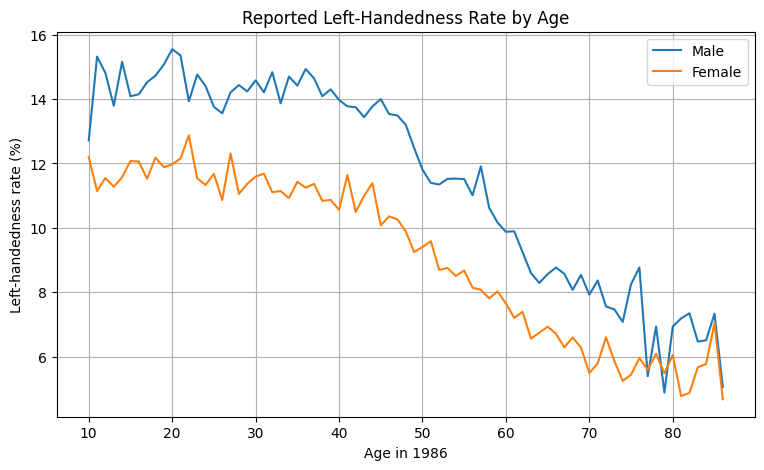

In [8]:
fig, ax = plt.subplots()

ax.plot(
    lefthanded_data["Age"],
    lefthanded_data["Male"],
    label="Male"
)
ax.plot(
    lefthanded_data["Age"],
    lefthanded_data["Female"],
    label="Female"
)

ax.set_title("Reported Left-Handedness Rate by Age")
ax.set_xlabel("Age in 1986")
ax.set_ylabel("Left-handedness rate (%)")
ax.legend()
plt.show()

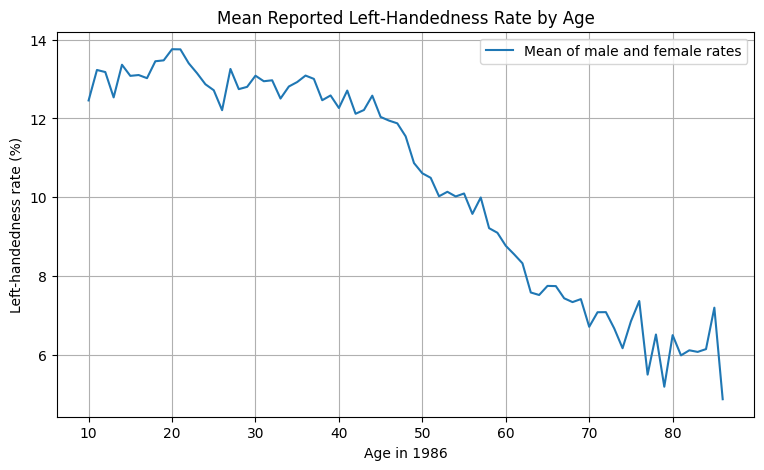

In [9]:
fig, ax = plt.subplots()

ax.plot(
    lefthanded_data["Age"],
    lefthanded_data["Mean_lh"],
    label="Mean of male and female rates"
)

ax.set_title("Mean Reported Left-Handedness Rate by Age")
ax.set_xlabel("Age in 1986")
ax.set_ylabel("Left-handedness rate (%)")
ax.legend()
plt.show()

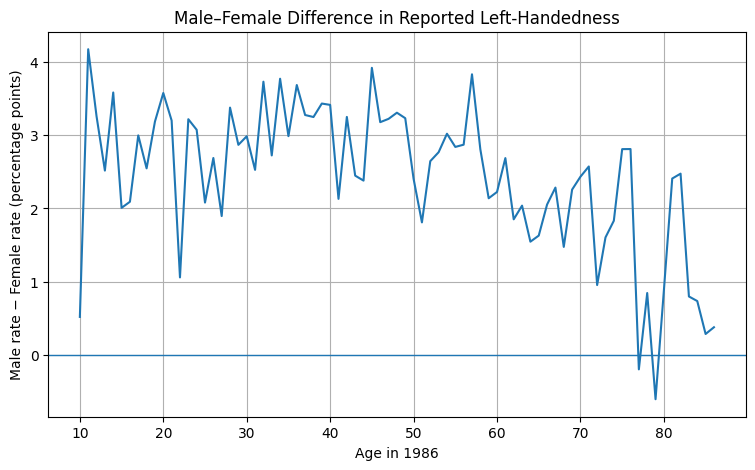

In [10]:
lefthanded_data["Sex_rate_gap"] = (
    lefthanded_data["Male"] - lefthanded_data["Female"]
)

fig, ax = plt.subplots()

ax.plot(
    lefthanded_data["Age"],
    lefthanded_data["Sex_rate_gap"]
)

ax.axhline(0, linewidth=1)
ax.set_title("Male–Female Difference in Reported Left-Handedness")
ax.set_xlabel("Age in 1986")
ax.set_ylabel("Male rate − Female rate (percentage points)")
plt.show()

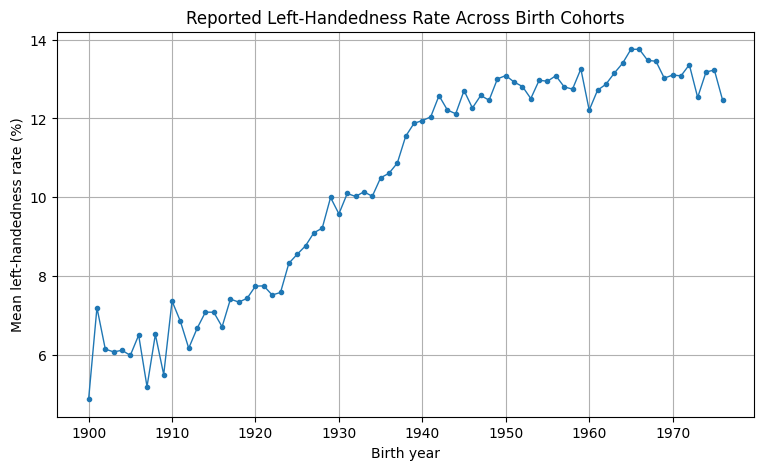

In [11]:
fig, ax = plt.subplots()

ax.plot(
    lefthanded_data["Birth_year"],
    lefthanded_data["Mean_lh"],
    marker="o",
    markersize=3,
    linewidth=1
)

ax.set_title("Reported Left-Handedness Rate Across Birth Cohorts")
ax.set_xlabel("Birth year")
ax.set_ylabel("Mean left-handedness rate (%)")
plt.show()

### EDA takeaway

The important pattern is not simply “older people are less left-handed.” The age pattern can also be interpreted as a **birth-cohort pattern**: different generations have different reported rates of left-handedness.

That distinction matters because a person’s age at death determines approximately which birth cohort they belong to:

$$
\text{Birth year} = \text{Study year} - \text{Age at death}
$$

The Bayesian model will use this relationship explicitly.

## 5. Exploratory Data Analysis — Mortality distribution

Next, inspect the U.S. mortality distribution that supplies the age weights.

`Both Sexes` is used as the total number of deaths at each age.

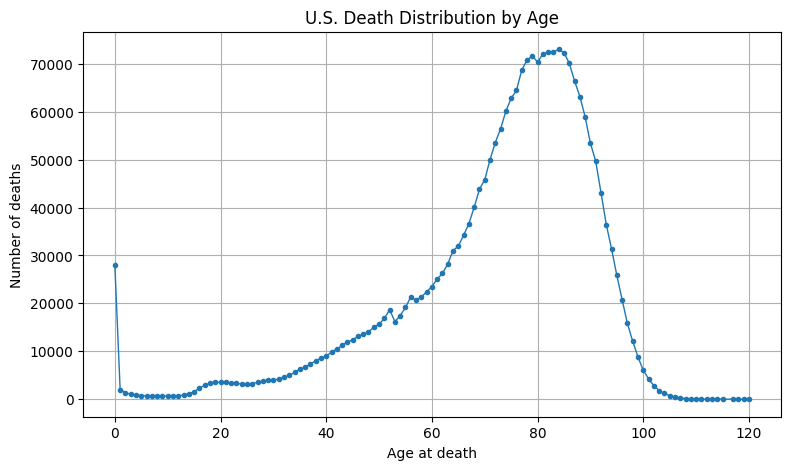

In [12]:
death_distribution_data = death_distribution_data.dropna(
    subset=["Age", "Both Sexes"]
).copy()

death_distribution_data["Age"] = death_distribution_data["Age"].astype(int)

fig, ax = plt.subplots()

ax.plot(
    death_distribution_data["Age"],
    death_distribution_data["Both Sexes"],
    marker="o",
    markersize=3,
    linewidth=1
)

ax.set_title("U.S. Death Distribution by Age")
ax.set_xlabel("Age at death")
ax.set_ylabel("Number of deaths")
plt.show()

Total deaths represented: 2391043
Probability check: 1.0


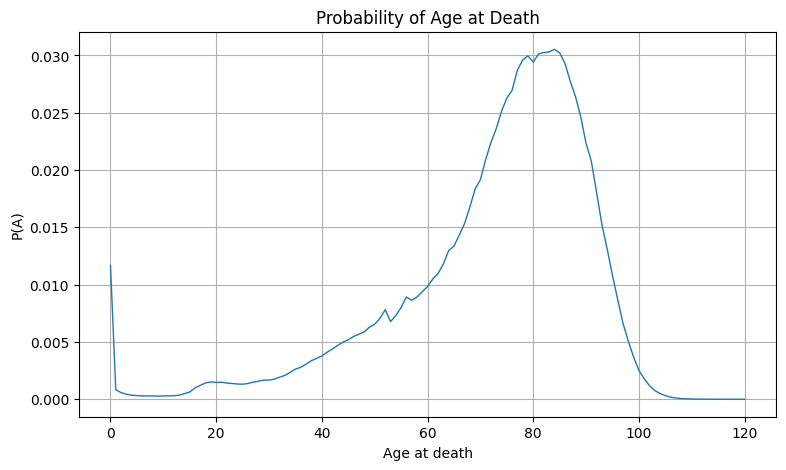

In [13]:
# Convert death counts into a probability distribution over age.
total_deaths = death_distribution_data["Both Sexes"].sum()

death_distribution_data["P_A"] = (
    death_distribution_data["Both Sexes"] / total_deaths
)

print("Total deaths represented:", int(total_deaths))
print("Probability check:", death_distribution_data["P_A"].sum())

fig, ax = plt.subplots()

ax.plot(
    death_distribution_data["Age"],
    death_distribution_data["P_A"],
    linewidth=1
)

ax.set_title("Probability of Age at Death")
ax.set_xlabel("Age at death")
ax.set_ylabel("P(A)")
plt.show()

In [14]:
# A compact age-band view helps describe where the mortality mass lies.
age_bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, np.inf]
age_labels = [
    "0–9", "10–19", "20–29", "30–39", "40–49",
    "50–59", "60–69", "70–79", "80–89", "90+"
]

death_distribution_data["Age_band"] = pd.cut(
    death_distribution_data["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_band_summary = (
    death_distribution_data
    .groupby("Age_band", observed=False)["Both Sexes"]
    .sum()
    .to_frame("Deaths")
)

age_band_summary["Share"] = (
    age_band_summary["Deaths"] / age_band_summary["Deaths"].sum()
)

display(age_band_summary)

,Deaths,Share
Age_band,,
0–9,36660.0,0.015332
10–19,17899.0,0.007486
20–29,34581.0,0.014463
30–39,60167.0,0.025163
40–49,120572.0,0.050427
50–59,189738.0,0.079354
60–69,320790.0,0.134163
70–79,604254.0,0.252716
80–89,691144.0,0.289055


## 6. Bayesian framework

Let:

- $LH$: the person is left-handed
- $RH$: the person is right-handed
- $A$: age at death

We first estimate:

$$
P(LH\mid A)
$$

Then calculate the overall probability:

$$
P(LH)=\sum_A P(LH\mid A)P(A)
$$

Finally, Bayes' theorem gives:

$$
P(A\mid LH)=
\frac{P(LH\mid A)P(A)}{P(LH)}
$$

For right-handers:

$$
P(A\mid RH)=
\frac{P(RH\mid A)P(A)}{P(RH)}
$$

where:

$$
P(RH\mid A)=1-P(LH\mid A)
$$

and:

$$
P(RH)=1-P(LH)
$$

## 7. Estimating $P(LH \mid A)$

For a hypothetical study conducted in `study_year`, an individual who dies at age $A$ was approximately born in:

$$
\text{Birth year}=\text{study year}-A
$$

The 1986 survey provides historical handedness rates by birth cohort. Where the requested cohort lies outside the observed range, the original modeling approach uses the mean of the nearest 10 observations as an extrapolation.

In [15]:
def P_lh_given_A(ages_of_death, study_year=1990):
    """
    Estimate P(LH | A) for each age at death.

    The 1986 survey is treated as a historical birth-cohort curve.
    For a chosen study year:
        birth_year = study_year - age_at_death

    Ages mapped to birth cohorts outside the observed 1900–1976
    range are assigned a boundary-rate estimate based on the
    nearest 10 observations.
    """
    ages = np.asarray(ages_of_death, dtype=int)

    # Boundary estimates used when a required birth cohort is outside the survey range.
    early_1900s_rate = lefthanded_data["Mean_lh"].tail(10).mean()
    late_1900s_rate = lefthanded_data["Mean_lh"].head(10).mean()

    birth_years = study_year - ages
    rate_by_birth_year = (
        lefthanded_data
        .set_index("Birth_year")["Mean_lh"]
    )

    middle_rates = rate_by_birth_year.reindex(birth_years).to_numpy()

    youngest_age = study_year - SURVEY_YEAR + 10
    oldest_age = study_year - SURVEY_YEAR + 86

    probabilities = np.full(
        ages.shape,
        np.nan,
        dtype=float
    )

    older_than_observed = ages > oldest_age
    younger_than_observed = ages < youngest_age
    within_observed_range = (
        (ages >= youngest_age) &
        (ages <= oldest_age)
    )

    probabilities[older_than_observed] = early_1900s_rate / 100
    probabilities[younger_than_observed] = late_1900s_rate / 100
    probabilities[within_observed_range] = (
        middle_rates[within_observed_range] / 100
    )

    return probabilities

### Check the cohort mapping

For example, with `study_year=1990`:

$$
A=50 \Rightarrow 1990-50=1940
$$

With `study_year=2018`:

$$
A=50 \Rightarrow 2018-50=1968
$$

So `study_year` changes **which birth cohort is associated with an age at death**. It does not load new mortality data.

In [16]:
example_ages = np.array([40, 50, 60, 70])

mapping_check = pd.DataFrame({
    "Age at death": example_ages,
    "Birth year — 1990 scenario": 1990 - example_ages,
    "Birth year — 2018 scenario": 2018 - example_ages
})

display(mapping_check)

probability_check = pd.DataFrame({
    "Age at death": example_ages,
    "P(LH | A) — 1990": P_lh_given_A(example_ages, 1990),
    "P(LH | A) — 2018": P_lh_given_A(example_ages, 2018)
})

display(probability_check)

,Age at death,Birth year — 1990 scenario,Birth year — 2018 scenario
0,40,1950,1978
1,50,1940,1968
2,60,1930,1958
3,70,1920,1948


,Age at death,P(LH | A) — 1990,P(LH | A) — 2018
0,40,0.130897,0.130906
1,50,0.119464,0.134533
2,60,0.095769,0.127450
3,70,0.077429,0.124633


## 8. Overall probability of left-handedness

The mortality distribution gives the age weights $P(A)$. We combine those weights with $P(LH\mid A)$:

$$
P(LH)=\sum_A P(LH\mid A)P(A)
$$

In code, this is implemented as a mortality-weighted average of the age-specific left-handedness probabilities.

In [17]:
def P_lh(death_distribution_data, study_year=1990):
    """
    Calculate the overall probability P(LH) for people in the
    modeled death distribution.
    """
    ages = death_distribution_data["Age"].to_numpy()
    death_counts = death_distribution_data["Both Sexes"].to_numpy()

    p_lh_given_a = P_lh_given_A(ages, study_year)

    weighted_left = death_counts * p_lh_given_a

    return np.sum(weighted_left) / np.sum(death_counts)

In [18]:
p_lh_1990 = P_lh(death_distribution_data, 1990)
p_lh_2018 = P_lh(death_distribution_data, 2018)

print(f"P(LH) — 1990 scenario: {p_lh_1990:.4f}")
print(f"P(LH) — 2018 scenario: {p_lh_2018:.4f}")

P(LH) — 1990 scenario: 0.0777
P(LH) — 2018 scenario: 0.1145


## 9. Conditional age-at-death distributions

Now all pieces required for Bayes' theorem are available:

- $P(LH\mid A)$: from the historical handedness curve
- $P(A)$: from the mortality distribution
- $P(LH)$: from the weighted sum above

Therefore:

$$
P(A\mid LH)=
\frac{P(LH\mid A)P(A)}{P(LH)}
$$

and:

$$
P(A\mid RH)=
\frac{P(RH\mid A)P(A)}{P(RH)}
$$

In [19]:
def P_A_given_lh(ages_of_death, death_distribution_data, study_year=1990):
    """
    Calculate P(A | LH), the probability distribution of age at death
    conditional on being left-handed.
    """
    ages = np.asarray(ages_of_death, dtype=int)

    death_by_age = (
        death_distribution_data
        .set_index("Age")["Both Sexes"]
        .reindex(ages)
        .to_numpy()
    )

    p_a = death_by_age / death_distribution_data["Both Sexes"].sum()
    p_left = P_lh(death_distribution_data, study_year)
    p_lh_given_a = P_lh_given_A(ages, study_year)

    return p_lh_given_a * p_a / p_left

In [20]:
def P_A_given_rh(ages_of_death, death_distribution_data, study_year=1990):
    """
    Calculate P(A | RH), the probability distribution of age at death
    conditional on being right-handed.
    """
    ages = np.asarray(ages_of_death, dtype=int)

    death_by_age = (
        death_distribution_data
        .set_index("Age")["Both Sexes"]
        .reindex(ages)
        .to_numpy()
    )

    p_a = death_by_age / death_distribution_data["Both Sexes"].sum()
    p_right = 1 - P_lh(death_distribution_data, study_year)
    p_rh_given_a = 1 - P_lh_given_A(ages, study_year)

    return p_rh_given_a * p_a / p_right

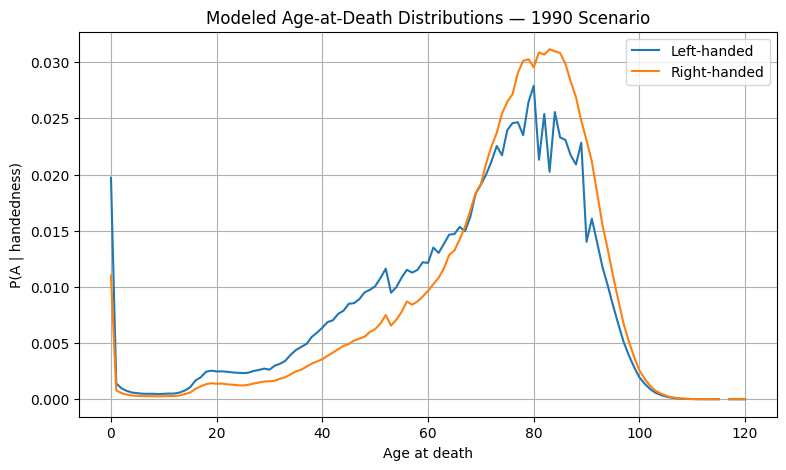

In [21]:
ages = np.arange(
    int(death_distribution_data["Age"].min()),
    int(death_distribution_data["Age"].max()) + 1
)

left_handed_probability = P_A_given_lh(
    ages,
    death_distribution_data,
    study_year=1990
)

right_handed_probability = P_A_given_rh(
    ages,
    death_distribution_data,
    study_year=1990
)

fig, ax = plt.subplots()

ax.plot(
    ages,
    left_handed_probability,
    label="Left-handed"
)
ax.plot(
    ages,
    right_handed_probability,
    label="Right-handed"
)

ax.set_title("Modeled Age-at-Death Distributions — 1990 Scenario")
ax.set_xlabel("Age at death")
ax.set_ylabel("P(A | handedness)")
ax.legend()
plt.show()

In [22]:
distribution_check = pd.DataFrame({
    "Group": ["Left-handed", "Right-handed"],
    "Probability sum": [
        np.nansum(left_handed_probability),
        np.nansum(right_handed_probability)
    ]
})

display(distribution_check)

,Group,Probability sum
0,Left-handed,1.0
1,Right-handed,1.0


## 10. Expected age at death

For a discrete probability distribution, the expected value is:

$$
E[A\mid LH]=\sum_A A\,P(A\mid LH)
$$

and:

$$
E[A\mid RH]=\sum_A A\,P(A\mid RH)
$$

This is a probability-weighted average age, not a directly observed life-expectancy estimate.

In [23]:
def expected_age(ages, probabilities):
    """Return the expected age from a discrete age distribution."""
    return np.nansum(
        np.asarray(ages) * np.asarray(probabilities)
    )

average_lh_age = expected_age(
    ages,
    left_handed_probability
)

average_rh_age = expected_age(
    ages,
    right_handed_probability
)

gap_1990 = average_rh_age - average_lh_age

print(f"Expected age at death — left-handed:  {average_lh_age:.1f} years")
print(f"Expected age at death — right-handed: {average_rh_age:.1f} years")
print(f"Apparent age-at-death gap — 1990:      {gap_1990:.1f} years")

Expected age at death — left-handed:  67.3 years
Expected age at death — right-handed: 72.8 years
Apparent age-at-death gap — 1990:      5.5 years


## 11. Modeled 2018 scenario

### What changes?

Only the `study_year` used in the handedness-to-birth-cohort mapping:

$$
\text{Birth year}=2018-A
$$

### What stays fixed?

The same mortality distribution is used. There is **no 2018 mortality dataset** in this notebook.

Therefore, the 2018 calculation should be interpreted as a **modeled/counterfactual study-year scenario**, not as an empirical estimate based on 2018 mortality records.

In [24]:
left_handed_probability_2018 = P_A_given_lh(
    ages,
    death_distribution_data,
    study_year=2018
)

right_handed_probability_2018 = P_A_given_rh(
    ages,
    death_distribution_data,
    study_year=2018
)

average_lh_age_2018 = expected_age(
    ages,
    left_handed_probability_2018
)

average_rh_age_2018 = expected_age(
    ages,
    right_handed_probability_2018
)

gap_2018 = average_rh_age_2018 - average_lh_age_2018

print(f"Expected age at death — left-handed:  {average_lh_age_2018:.1f} years")
print(f"Expected age at death — right-handed: {average_rh_age_2018:.1f} years")
print(f"Apparent age-at-death gap — 2018:      {gap_2018:.1f} years")

Expected age at death — left-handed:  70.3 years
Expected age at death — right-handed: 72.6 years
Apparent age-at-death gap — 2018:      2.3 years


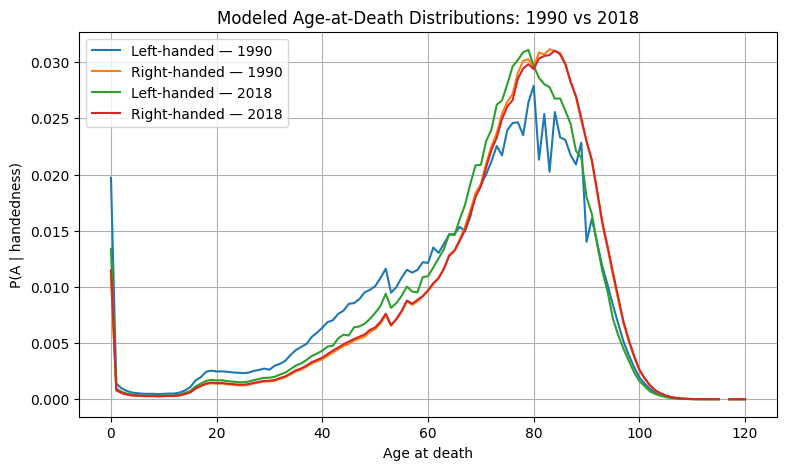

In [25]:
fig, ax = plt.subplots()

ax.plot(
    ages,
    left_handed_probability,
    label="Left-handed — 1990"
)
ax.plot(
    ages,
    right_handed_probability,
    label="Right-handed — 1990"
)
ax.plot(
    ages,
    left_handed_probability_2018,
    label="Left-handed — 2018"
)
ax.plot(
    ages,
    right_handed_probability_2018,
    label="Right-handed — 2018"
)

ax.set_title("Modeled Age-at-Death Distributions: 1990 vs 2018")
ax.set_xlabel("Age at death")
ax.set_ylabel("P(A | handedness)")
ax.legend()
plt.show()

## 12. Study-year sensitivity analysis

The 1990 and 2018 values are not two randomly selected mortality datasets. They are two points on the same modeling framework.

A useful diagnostic is to evaluate several hypothetical study years and see whether the apparent gap changes systematically as the study year moves forward.

This is still using the **same mortality distribution**; only the birth-cohort mapping changes.

In [26]:
study_years = np.arange(1990, 2019)

sensitivity_rows = []

for year in study_years:
    lh_prob = P_A_given_lh(
        ages,
        death_distribution_data,
        study_year=year
    )
    rh_prob = P_A_given_rh(
        ages,
        death_distribution_data,
        study_year=year
    )

    lh_age = expected_age(ages, lh_prob)
    rh_age = expected_age(ages, rh_prob)

    sensitivity_rows.append({
        "Study year": year,
        "Expected age — LH": lh_age,
        "Expected age — RH": rh_age,
        "Apparent gap": rh_age - lh_age
    })

sensitivity = pd.DataFrame(sensitivity_rows)

display(sensitivity.head())
display(sensitivity.tail())

,Study year,Expected age — LH,Expected age — RH,Apparent gap
0,1990,67.256022,72.798148,5.542126
1,1991,67.260819,72.803378,5.542558
2,1992,67.285316,72.807322,5.522006
3,1993,67.312255,72.811142,5.498888
4,1994,67.349991,72.814213,5.464222


,Study year,Expected age — LH,Expected age — RH,Apparent gap
24,2014,69.693285,72.695107,3.001822
25,2015,69.846804,72.680811,2.834007
26,2016,69.999563,72.665969,2.666407
27,2017,70.148671,72.650974,2.502303
28,2018,70.295196,72.635692,2.340496


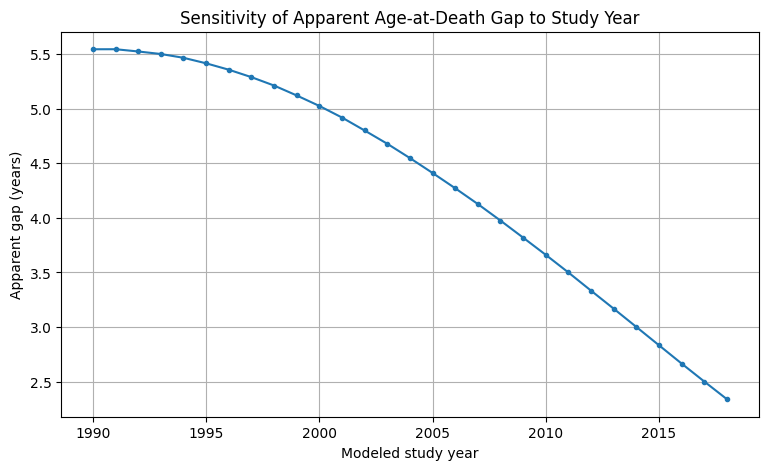

In [27]:
fig, ax = plt.subplots()

ax.plot(
    sensitivity["Study year"],
    sensitivity["Apparent gap"],
    marker="o",
    markersize=3
)

ax.set_title("Sensitivity of Apparent Age-at-Death Gap to Study Year")
ax.set_xlabel("Modeled study year")
ax.set_ylabel("Apparent gap (years)")
plt.show()

### How to interpret the sensitivity analysis

If the apparent gap changes as `study_year` changes, that demonstrates that the result is sensitive to the **historical birth-cohort handedness curve**.

This does **not**, by itself, prove a causal statement about mortality.

The strongest interpretation supported by this modeling framework is:

> **Historical changes in reported handedness across birth cohorts can create a substantial apparent age-at-death difference even when the mortality distribution itself is held fixed.**

## 13. Final results

The key outputs can be summarized in one table.

| Scenario | Mortality distribution | Handedness mapping | Apparent age-at-death gap |
|---|---|---|---:|
| 1990 | Fixed U.S. mortality distribution | $1990-A$ | ~5.5 years |
| 2018 | Same fixed U.S. mortality distribution | $2018-A$ | ~2.3 years |

The exact displayed value may vary slightly with data/version details and floating-point calculations.

In [28]:
results = pd.DataFrame({
    "Scenario": ["1990", "2018"],
    "Expected age — LH": [average_lh_age, average_lh_age_2018],
    "Expected age — RH": [average_rh_age, average_rh_age_2018],
    "Apparent gap": [gap_1990, gap_2018]
})

display(
    results.style.format({
        "Expected age — LH": "{:.1f}",
        "Expected age — RH": "{:.1f}",
        "Apparent gap": "{:.1f}"
    })
)

,Scenario,Expected age — LH,Expected age — RH,Apparent gap
0,1990,67.3,72.8,5.5
1,2018,70.3,72.6,2.3


## 14. Interpretation and limitations

### What the model demonstrates

The analysis shows how an apparent left-vs-right age-at-death difference can emerge from the interaction of:

$$
\text{Birth-cohort handedness rates}
+
\text{Age-at-death distribution}
$$

rather than requiring an explicit assumption that left-handed people have higher mortality.

### Important limitations

- The handedness curve comes from one historical 1986 survey.
- The mortality distribution is held fixed for the modeled study-year comparisons.
- Birth cohorts outside the directly observed survey range are extrapolated using boundary averages.
- The model estimates **age-at-death distributions**; it should not be presented as a direct causal estimate of life expectancy.
- A changing modeled gap is evidence of sensitivity to cohort structure, not proof of causality or proof that handedness has zero biological effect.

### Interview-ready conclusion

> The apparent age-at-death gap is sensitive to historical changes in reported handedness across birth cohorts. By changing only the modeled study year while holding the mortality distribution fixed, the analysis shows that cohort structure alone can generate a substantial apparent difference.

## 15. Reproducibility checklist

Before presenting this project in an interview, I should be able to explain:

- Why age is converted into birth year.
- What $P(LH\mid A)$ means.
- Why `P_lh()` is a mortality-weighted average.
- Why Bayes' theorem is needed to obtain $P(A\mid LH)$.
- Why `study_year=2018` does not mean 2018 mortality data.
- Why the 2018 result is a modeled/counterfactual scenario.
- Why changing birth-cohort handedness rates can change the apparent age-at-death gap.

## References

**Project implementation:**  
https://github.com/shukkkur/Do-Left-Handed-People-Die-Young

**1986 handedness data used by the implementation:**  
https://gist.githubusercontent.com/mbonsma/8da0990b71ba9a09f7de395574e54df1/raw/aec88b30af87fad8d45da7e774223f91dad09e88/lh_data.csv

**U.S. mortality distribution used by the implementation:**  
https://gist.githubusercontent.com/mbonsma/2f4076aab6820ca1807f4e29f75f18ec/raw/62f3ec07514c7e31f5979beeca86f19991540796/cdc_vs00199_table310.tsv

**Related research:**  
https://pmc.ncbi.nlm.nih.gov/articles/PMC10369838/